# Kinetic Models in MEWpy

Author: Vitor Pereira.

License: [CC BY-SA 4.0](http://creativecommons.org/licenses/by-sa/4.0/)

-------

This notebook shows how MEWpy simulates SBML kinetic models and uses them for strain design optimization.

## Checking and setting the ODE solver

MEWpy has interfaces to the **scipy**, **scikits.odes** and **odespy** ODE solvers. The scipy interface uses `solve_ivp` with the LSODA method by default, which switches automatically between stiff and non-stiff integration. [scikits.odes](https://scikits-odes.readthedocs.io/en/latest/), which uses [SUNDIALS](https://computing.llnl.gov/projects/sundials), is an alternative for stiff systems.

The ODE solvers available:

In [1]:
from mewpy.solvers import ode_solvers, set_default_ode_solver, get_default_ode_solver

In [2]:
ode_solvers()

['scipy']

The default solver:

In [3]:
get_default_ode_solver()

'scipy'

which can be changed:

In [4]:
set_default_ode_solver('scipy')

## Loading and browsing an SBML model

Start by loading the SBML kinetic model:

In [5]:
from mewpy.io.sbml import load_ODEModel
model = load_ODEModel('models/kinetic/chassagnole2002.xml')

The SBML file is loaded into an `ODEModel`. Its metabolites and their initial concentrations (`y0`):

In [6]:
model.find_metabolites()

,name,compartment,formula,charge,y0
id,,,,,
cpep,Phosphoenol pyruvate,cytosol,,,2.670
cglcex,Extracellular Glucose,extracellular,,,2.000
cg6p,Glucose-6-Phosphate,cytosol,,,3.480
cpyr,Pyruvate,cytosol,,,2.670
cf6p,Fructose-6-Phosphate,cytosol,,,0.600
cg1p,Glucose-1-Phosphate,cytosol,,,0.653
cpg,6-Phosphogluconate,cytosol,,,0.808
cfdp,"Fructose-1,6-bisphosphate",cytosol,,,0.272
csed7p,sedoheptulose-7-phosphate,cytosol,,,0.276


and the reactions:

In [7]:
model.find()

,name,stoichiometry,law,reversible,parameters,modifiers
id,,,,,,
vPTS,Phosphotransferase system,"{'cglcex': -1.0, 'cpep': -1.0, 'cg6p': 1.0, 'c...",extracellular * rmaxPTS * cglcex * (cpep / cpy...,False,"{'rmaxPTS': 7829.78, 'KPTSa1': 3082.3, 'KPTSa2...",[]
vPGI,Glucose-6-phosphate isomerase,"{'cg6p': -1.0, 'cf6p': 1.0}",cytosol * rmaxPGI * (cg6p - cf6p / KPGIeq) / (...,True,"{'rmaxPGI': 650.9878687, 'KPGIeq': 0.1725, 'KP...",[cpg]
vPGM,Phosphoglucomutase,"{'cg6p': -1.0, 'cg1p': 1.0}",cytosol * rmaxPGM * (cg6p - cg1p / KPGMeq) / (...,True,"{'rmaxPGM': 0.8398242773, 'KPGMeq': 0.196, 'KP...",[]
vG6PDH,Glucose-6-phosphate dehydrogenase,"{'cg6p': -1.0, 'cpg': 1.0}",cytosol * rmaxG6PDH * cg6p * cnadp / ((cg6p + ...,False,"{'rmaxG6PDH': 1.380196955, 'KG6PDHg6p': 14.4, ...",[]
vPFK,Phosphofructokinase,"{'cf6p': -1.0, 'cfdp': 1.0}",cytosol * rmaxPFK * catp * cf6p / ((catp + KPF...,False,"{'rmaxPFK': 1840.584747, 'KPFKatps': 0.123, 'K...",[cpep]
vTA,Transaldolase,"{'cgap': -1.0, 'csed7p': -1.0, 'cf6p': 1.0, 'c...",cytosol * rmaxTA * (cgap * csed7p - ce4p * cf6...,True,"{'rmaxTA': 10.87164108, 'KTAeq': 1.05}",[]
vTKA,Transketolase a,"{'crib5p': -1.0, 'cxyl5p': -1.0, 'cgap': 1.0, ...",cytosol * rmaxTKa * (crib5p * cxyl5p - csed7p ...,True,"{'rmaxTKa': 9.473384783, 'KTKaeq': 1.2}",[]
vTKB,Transketolase b,"{'ce4p': -1.0, 'cxyl5p': -1.0, 'cgap': 1.0, 'c...",cytosol * rmaxTKb * (cxyl5p * ce4p - cf6p * cg...,True,"{'rmaxTKb': 86.55855855, 'KTKbeq': 10.0}",[]
vMURSyNTH,Mureine synthesis,{'cf6p': -2.0},cytosol * rmaxMurSynth,False,{'rmaxMurSynth': 0.00043711},[]


The reactions may be filtered by an id pattern:

In [8]:
model.find('vPTS')

,name,stoichiometry,law,reversible,parameters,modifiers
id,,,,,,
vPTS,Phosphotransferase system,"{'cglcex': -1.0, 'cpep': -1.0, 'cg6p': 1.0, 'c...",extracellular * rmaxPTS * cglcex * (cpep / cpy...,False,"{'rmaxPTS': 7829.78, 'KPTSa1': 3082.3, 'KPTSa2...",[]


and so may the parameters:

In [9]:
model.find_parameters('rmax')

,Value
Parameter,
rmaxPTS,7829.780000
rmaxPGI,650.987869
rmaxPGM,0.839824
rmaxG6PDH,1.380197
rmaxPFK,1840.584747
rmaxTA,10.871641
rmaxTKa,9.473385
rmaxTKb,86.558559
rmaxMurSynth,0.000437


### Model Reactions

You may access each reaction programmatically:

In [10]:
model.reactions.vPTS

((((extracellular*7829.78)*cglcex)*(cpep/cpyr))/((((3082.3+(0.01*(cpep/cpyr)))+(245.3*cglcex))+(cglcex*(cpep/cpyr)))*(1+(pow(cg6p,3.66)/2.15))))

List the substrate and product metabolites:

In [11]:
model.reactions.vPTS.substrates

['cglcex', 'cpep']

In [12]:
model.reactions.vPTS.products

['cg6p', 'cpyr']

as well as the parameters and their default values:

In [13]:
model.reactions.vPTS.parameters

OrderedDict([('rmaxPTS', 7829.78),
             ('KPTSa1', 3082.3),
             ('KPTSa2', 0.01),
             ('KPTSa3', 245.3),
             ('nPTSg6p', 3.66),
             ('KPTSg6p', 2.15)])

Parameters may be renamed, for example to avoid a name conflict when adding a reaction to the model. The renaming changes the model; the rate law is printed with the parameter values, so it looks the same:

In [14]:
model.reactions.vPTS.rename_parameter('rmaxPTS','rmaxPTS_renamed')
model.reactions.vPTS

((((extracellular*7829.78)*cglcex)*(cpep/cpyr))/((((3082.3+(0.01*(cpep/cpyr)))+(245.3*cglcex))+(cglcex*(cpep/cpyr)))*(1+(pow(cg6p,3.66)/2.15))))

In [15]:
# restore the original name, used in the rest of the notebook
model.reactions.vPTS.rename_parameter('rmaxPTS_renamed', 'rmaxPTS')

The rate law with the reaction's parameter values:

In [16]:
model.reactions.vPTS.replace()

'((((extracellular * 7829.78) * cglcex) * (cpep / cpyr)) / ((((3082.3 + (0.01 * (cpep / cpyr))) + (245.3 * cglcex)) + (cglcex * (cpep / cpyr))) * (1 + (pow(cg6p , 3.66) / 2.15))))'

or in LaTeX:

In [17]:
model.reactions.vPTS.replace(latex=True)

\frac {\textrm{extracellular} \times 7829.78 \times \textrm{cglcex} \times \frac {\textrm{cpep}} {\textrm{cpyr}}} {\mathopen{}\left( 3082.3 + 0.01 \times \frac {\textrm{cpep}} {\textrm{cpyr}} + 245.3 \times \textrm{cglcex} + \textrm{cglcex} \times \frac {\textrm{cpep}} {\textrm{cpyr}} \mathclose{}\right) \times \mathopen{}\left( \textrm{1} + \frac {{\textrm{cg6p}}^{3.66}} {2.15} \mathclose{}\right)}

MEWpy also computes reaction rates. With the model's parameter values and initial concentrations:

In [18]:
model.reactions.vPTS.calculate_rate()

6.238284215661543

or with other concentrations (`substrates`, for any metabolite in the rate law) and parameter values (`parameters`; `extracellular` is the size of the extracellular compartment):

In [19]:
model.reactions.vPTS.calculate_rate(parameters={'extracellular':70},substrates={'cg6p':5})

1.8123670461913133

## Kinetic simulations

Kinetic simulations are run by a `KineticSimulation` object:

In [20]:
from mewpy.simulation.kinetic import KineticSimulation

In [21]:
sim = KineticSimulation(model,timeout=0) 

Options for all its simulations:
- *parameters*, a dictionary of parameter values that replace the model's values;
- *t_points*, the integration time points, e.g. `[1,2,3,4,5]`, or a time span, `[start, end]`;
- *timeout*, the integration timeout in seconds; `timeout=0` sets no timeout.

A time span is divided into a configurable number of time steps:

In [22]:
from mewpy.solvers import SolverConfigurations

SolverConfigurations.N_STEPS

20

In [23]:
SolverConfigurations.N_STEPS = 30
SolverConfigurations.N_STEPS

30

The time points may also be set for all simulations; here, 20 points evenly spaced between 0 and 600:

In [24]:
sim.set_time(0,600,20)
sim.get_time_points()

array([  0.        ,  31.57894737,  63.15789474,  94.73684211,
       126.31578947, 157.89473684, 189.47368421, 221.05263158,
       252.63157895, 284.21052632, 315.78947368, 347.36842105,
       378.94736842, 410.52631579, 442.10526316, 473.68421053,
       505.26315789, 536.84210526, 568.42105263, 600.        ])

or for a single simulation:

In [25]:
res = sim.simulate(t_points=range(0,800,50))

The reaction rates at the last time point (t = 750), when the concentrations have nearly stopped changing (see the plots below):

In [26]:
res.find()

,Flux rate
Reaction ID,
vPTS,2.004974e-01
vPGI,5.832275e-02
vPGM,2.364509e-03
vG6PDH,1.397945e-01
vPFK,1.414158e-01
vTA,4.548674e-02
vTKA,4.549748e-02
vTKB,3.848310e-02
vMURSyNTH,4.371100e-04


Individual rates, by id or pattern:

In [27]:
print(res.fluxes['vPTS'])
# or
res.find('vPTS')

0.20049744050232046


,Flux rate
Reaction ID,
vPTS,0.200497


Metabolite concentrations over time, for one or more metabolites:

<Axes: xlabel='Time', ylabel='Glyceraldehyde-3-Phosphate'>

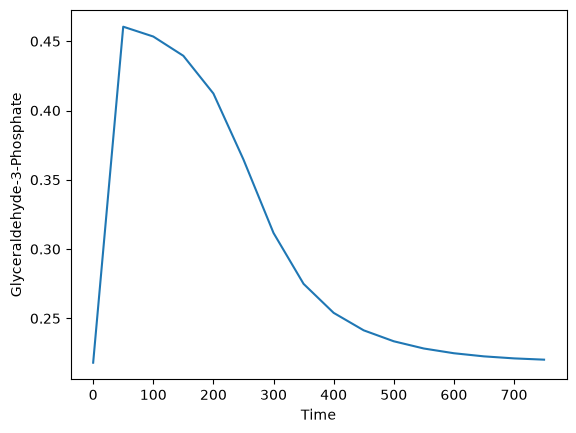

In [28]:
res.plot('cgap')

<Axes: xlabel='Time', ylabel='Extracellular Glucose'>

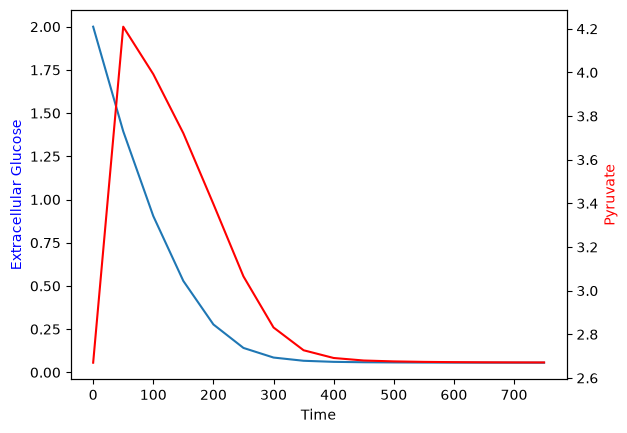

In [29]:
res.plot(['cglcex','cpyr'])

<Axes: xlabel='Time', ylabel='Concentrations'>

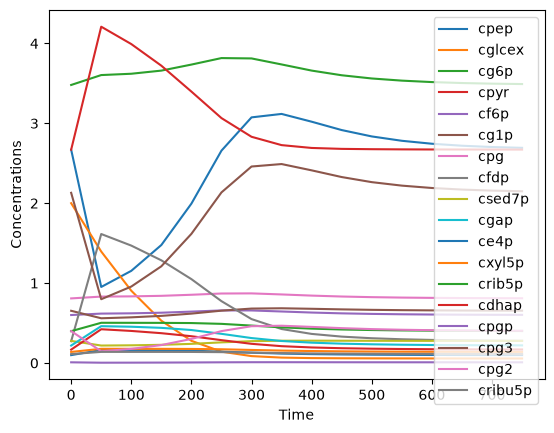

In [30]:
res.plot()

The concentrations at each time point:

In [31]:
res.get_y('cglcex')

array([2.        , 1.39497361, 0.90431031, 0.52880517, 0.27713827,
       0.14126651, 0.08565947, 0.06699221, 0.06080813, 0.05842793,
       0.05735383, 0.0567253 , 0.05634473, 0.05611004, 0.05596496,
       0.05587538])

As a dataframe, which can be saved to an Excel or CSV file:

In [32]:
import pandas as pd
pd.DataFrame(res.get_y('cglcex'),columns=['Concentration'],index=res.t)

,Concentration
0,2.000000
50,1.394974
100,0.904310
150,0.528805
200,0.277138
250,0.141267
300,0.085659
350,0.066992
400,0.060808
450,0.058428


### Modifying initial concentrations and parameters

A simulation may also take:
- *initcon*, a dictionary of initial concentrations, for some or all metabolites;
- *parameters*, a dictionary of parameter values;
- *factors*, a dictionary of factors that multiply parameter values.

Changing an initial concentration:

In [33]:
model.find_metabolites('cglcex')

,name,compartment,formula,charge,y0
id,,,,,
cglcex,Extracellular Glucose,extracellular,,,2.0


<Axes: xlabel='Time', ylabel='Concentrations'>

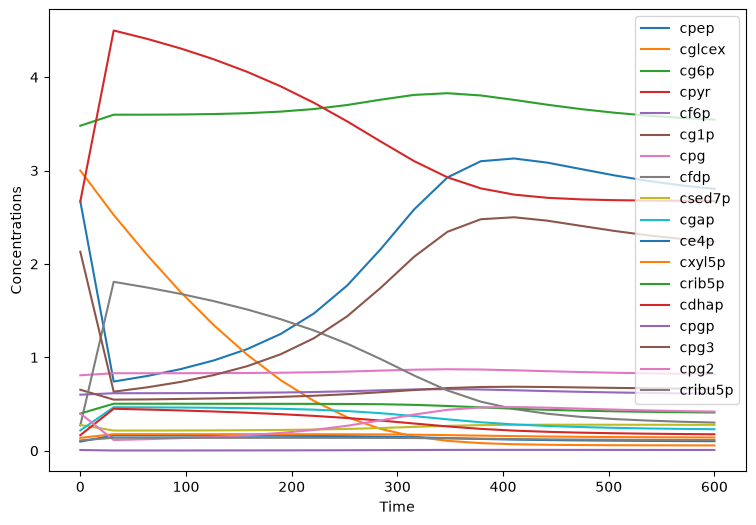

In [34]:
initcon = {'cglcex':3.0}
res = sim.simulate(initcon=initcon)
res.plot(size=(9,6))

Setting a new value for a parameter, for one simulation:

In [35]:
model.find_parameters('rmaxPK')

,Value
Parameter,
rmaxPK,0.061132


<Axes: xlabel='Time', ylabel='Concentrations'>

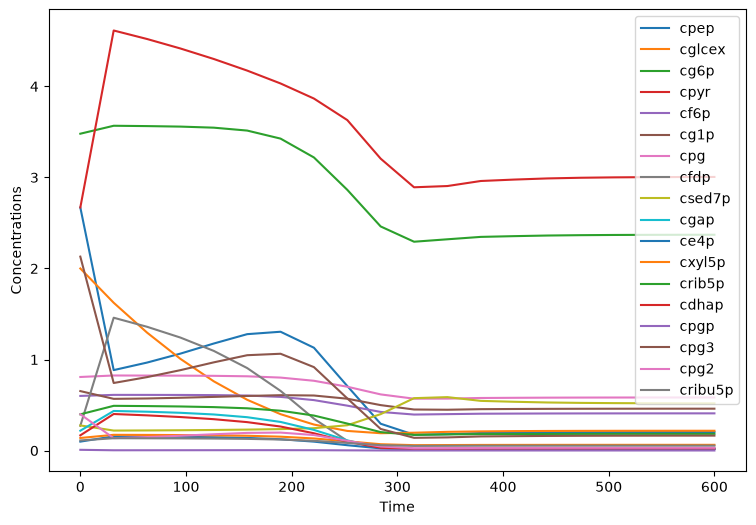

In [36]:
parameters = {'rmaxPK':0.61132}
res = sim.simulate(parameters=parameters)
res.plot(size=(9,6))

Multiplying a parameter by a factor. If a parameter is given both a new value and a factor, the factor multiplies the new value.

<Axes: xlabel='Time', ylabel='Concentrations'>

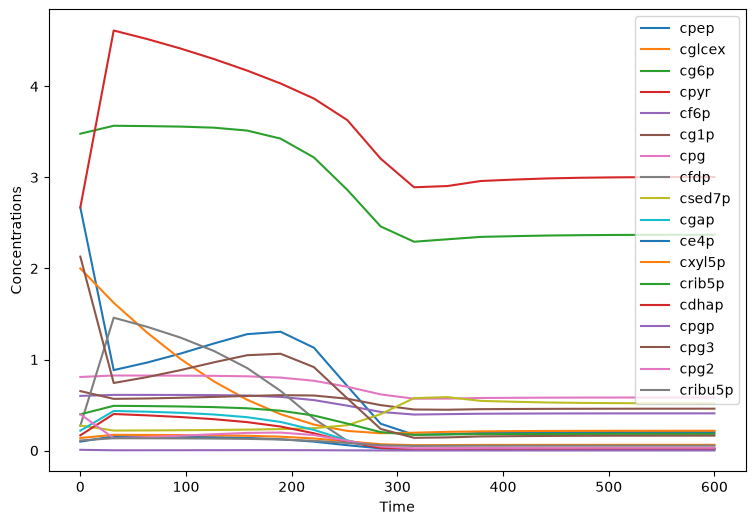

In [37]:
factors = {'rmaxPK': 10}  # 10-fold
res = sim.simulate(factors=factors)
res.plot(size=(9,6))

### Parameter scan

A scan shows how much a parameter controls a flux. Here, the steady-state serine synthesis flux (`vsersynth`) is computed while the Vmax of serine synthesis, pyruvate kinase or PEP carboxylase is scaled. A time span of `[0, 1e9]` gives the steady state:

,rmaxSerSynth,rmaxPK,rmaxpepCxylase
fold,,,
0.25,0.004555,0.018852,0.019374
0.50,0.008998,0.018473,0.018751
1.00,0.017506,0.017506,0.017506
2.00,0.032837,0.014771,0.015085
4.00,0.056505,0.008832,0.011581
8.00,0.083629,0.004418,0.007998


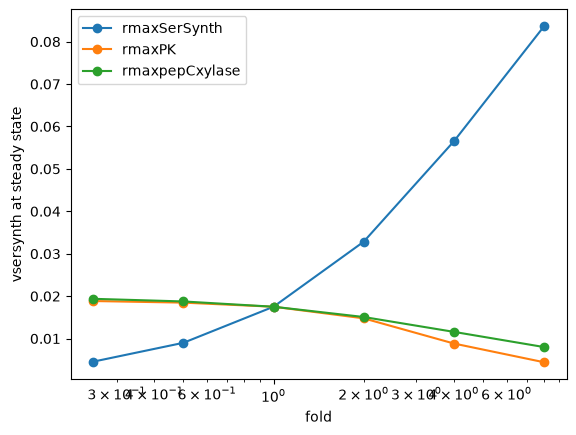

In [38]:
import pandas as pd

steady = KineticSimulation(model, t_points=[0, 1e9], timeout=0)
folds = [0.25, 0.5, 1, 2, 4, 8]

scan = pd.DataFrame({p: [steady.simulate(factors={p: f}).fluxes['vsersynth'] for f in folds]
                     for p in ['rmaxSerSynth', 'rmaxPK', 'rmaxpepCxylase']},
                    index=pd.Index(folds, name='fold'))
scan.plot(logx=True, marker='o', ylabel='vsersynth at steady state')
scan

Serine synthesis increases with its own Vmax, less than proportionally at high folds. Lowering pyruvate kinase or PEP carboxylase increases it slightly, and raising them decreases it.

## Strain Design Optimization with SBML kinetic models

In [39]:
import logging
from mewpy.problems import KineticOUProblem
from mewpy.optimization.evaluation import TargetFlux
from mewpy.optimization import EA

# jMetalPy logs each EA phase at DEBUG level; show its warnings only
logging.getLogger('jmetal').setLevel(logging.WARNING)

A Vmax is the product of an enzyme's concentration and its turnover number, so changing a Vmax models a change in the enzyme's level. By default, `KineticOUProblem` targets the parameters whose name contains "max", here the 30 `rmax` parameters; a `target` list may be given instead.

The objective is the serine synthesis flux. With more than 3 or 4 objectives, consider combining some with `AggregatedSum`.

In [40]:
objectives = [TargetFlux('vsersynth')]

The levels that may be applied to the targets; 0 is a knockout:

In [41]:
import numpy as np
levels = [round(float(x), 1) for x in np.arange(0, 3, 0.2)]
levels

[0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.6, 2.8]

The problem evaluates each candidate at steady state (`t_points=[0, 1e9]`); `timeout=0` sets no integration timeout:

In [42]:
problem = KineticOUProblem(model, objectives, t_points=[0, 1e9], timeout=0, levels=levels)

The EA runs 20 generations of 100 candidates, small settings so that the example runs quickly; use more generations in practice. `seed` sets the EA's random number generators. EAs are stochastic, so each run can return different solutions; the results discussed here are those of this run:

In [43]:
ea = EA(problem, max_generations=20, seed=42)

To run the optimization, just call the run method:

In [44]:
population = ea.run()

2026-11-09 23:27:52,212	INFO util.py:155 -- Outdated packages:
  ipywidgets==7.8.5 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-09 23:27:52,620	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-11-09 23:27:56,840	INFO worker.py:2038 -- Started a local Ray instance.


The final population, best first:

In [45]:
df = ea.dataframe()
df.sort_values('TargetFlux', ascending=False)

,Modification,Size,TargetFlux
0,"{'rmaxG3PDH': 0.0, 'rmaxG6PDH': 0.2, 'rmaxDAHP...",8,0.064333
1,"{'rmaxG3PDH': 0.0, 'rmaxPK': 0.6, 'rmaxG6PDH':...",8,0.064122
2,"{'rmaxDAHPS': 0.0, 'rmaxGAPDH': 2.6, 'rmaxpepC...",6,0.063405
3,"{'rmaxG3PDH': 0.0, 'rmaxPGluMu': 0.8, 'rmaxG6P...",8,0.062395
4,"{'rmaxG3PDH': 0.0, 'rmaxPGluMu': 0.8, 'rmaxG6P...",9,0.062012
5,"{'rmaxG3PDH': 0.0, 'rmaxPGluMu': 0.8, 'rmaxG6P...",10,0.061926
6,"{'rmaxG3PDH': 0.0, 'rmaxG6PDH': 0.2, 'rmaxPK':...",10,0.061917
7,"{'rmaxG3PDH': 0.0, 'rmaxG6PDH': 0.2, 'rmaxPK':...",10,0.061916
8,"{'rmaxG3PDH': 0.0, 'rmaxPGluMu': 0.8, 'rmaxPDH...",9,0.061891
9,"{'rmaxG3PDH': 0.0, 'rmaxPGluMu': 0.8, 'rmaxG6P...",8,0.061889


The best candidate raises the steady-state serine synthesis flux from 0.0175 (the wild type, see the scan above) to 0.0643. A candidate whose simulation fails, for example with NaN concentrations or rates, gets status ERROR and the worst fitness.

The best solution compared with the wild type, at steady state:

In [46]:
best = df.sort_values('TargetFlux', ascending=False).iloc[0]['Modification']
print(best)

wild_type = steady.simulate()
mutant = steady.simulate(factors=best)
pd.DataFrame({'wild type': wild_type.fluxes, 'best solution': mutant.fluxes}).loc[
    ['vPTS', 'vsersynth', 'vPK', 'vpepCxylase', 'vPDH']]

{'rmaxG3PDH': 0.0, 'rmaxG6PDH': 0.2, 'rmaxDAHPS': 0.0, 'rmaxGAPDH': 2.6, 'rmaxPK': 0.4, 'rmaxSynth1': 0.0, 'rmaxpepCxylase': 0.4, 'rmaxSerSynth': 2.8}


,wild type,best solution
vPTS,0.200404,0.200122
vsersynth,0.017506,0.064333
vPK,0.038117,0.016530
vpepCxylase,0.043229,0.062888
vPDH,0.188185,0.166814


and its concentrations over time, from the initial state:

<Axes: xlabel='Time', ylabel='Concentrations'>

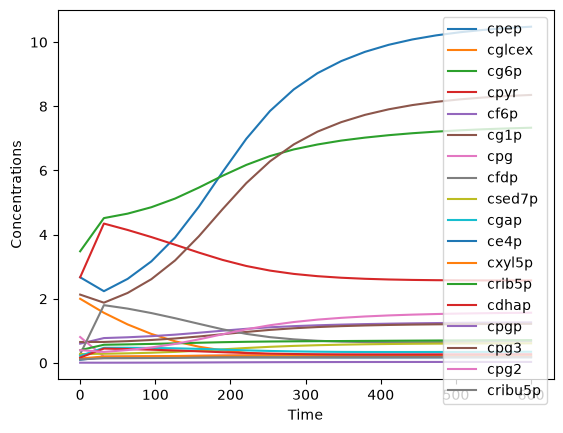

In [47]:
sim.simulate(factors=best).plot()